# Insight Hunters (VGG16 Model Development)

## Purpose

This notebook develops and trains a VGG16 transfer-learning model for binary tuberculosis classification using the prepared Shenzhen and Montgomery chest X-ray dataset.

The model follows the Insight Hunters common model experiment protocol to ensure a controlled comparison with ResNet50, DenseNet121 and EfficientNet-B0.

### Dataset

- Total images: 800
- Training: 560
- Validation: 120
- Testing: 120

Classes:
  - 0 = TB Negative
  - 1 = TB Positive

Input size: 224 × 224 × 3

### Experimental Rules

- Random seed: 42
- Batch size: 32
- ImageNet pretrained weights
- Training-only data augmentation
- Stage 1 uses a frozen pretrained convolutional base
- Validation loss is used for early stopping and checkpointing
- The test set remains locked during model development
- Fine-tuning is performed only after Stage 1
- Final outputs follow the shared Insight Hunters output structure

In [ ]:
# VGG16(Environment and GPU check)

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import random
import time
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# GPU information

gpus = tf.config.list_physical_devices("GPU")

print("=" * 65)
print("VGG16 - ENVIRONMENT CHECK")
print("=" * 65)

print(f"TensorFlow version: {tf.__version__}")
print(f"Random seed:        {SEED}")

if gpus:
    print(f"GPU detected:       YES")
    print(f"GPU device:         {gpus[0].name}")
else:
    print("GPU detected:       NO")

print("=" * 65)

Mounted at /content/drive
VGG16 - ENVIRONMENT CHECK
TensorFlow version: 2.20.0
Random seed:        42
GPU detected:       YES
GPU device:         /physical_device:GPU:0


In [ ]:
# VGG16 (Dataset path configuration)

# Project directories
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Insight_Hunters_Project"
)

DATA_SPLIT_ROOT = PROJECT_ROOT / "02_Data_Splits"

TRAIN_DIR = DATA_SPLIT_ROOT / "train"
VAL_DIR = DATA_SPLIT_ROOT / "val"

# Expected class folders
EXPECTED_CLASSES = [
    "tb_negative",
    "tb_positive"
]

# Expected image counts
EXPECTED_TRAIN_SIZE = 560
EXPECTED_VAL_SIZE = 120

# Verifying the directories

print("=" * 65)
print("VGG16 - DATASET PATH VERIFICATION")
print("=" * 65)

for directory_name, directory in [
    ("Training", TRAIN_DIR),
    ("Validation", VAL_DIR)
]:
    if not directory.exists():
        raise FileNotFoundError(
            f"{directory_name} directory not found:\n{directory}"
        )

    class_folders = sorted(
        folder.name
        for folder in directory.iterdir()
        if folder.is_dir()
    )

    if class_folders != EXPECTED_CLASSES:
        raise ValueError(
            f"{directory_name} class folders are incorrect.\n"
            f"Expected: {EXPECTED_CLASSES}\n"
            f"Found: {class_folders}"
        )

    print(f"✓ {directory_name} directory")
    print(f"  Classes: {class_folders}")

print()
print("TEST SET: NOT LOADED — LOCKED FOR FINAL EVALUATION")

print("=" * 65)
print("DATASET PATH VERIFICATION PASSED")

VGG16 - DATASET PATH VERIFICATION
✓ Training directory
  Classes: ['tb_negative', 'tb_positive']
✓ Validation directory
  Classes: ['tb_negative', 'tb_positive']

TEST SET: NOT LOADED — LOCKED FOR FINAL EVALUATION
DATASET PATH VERIFICATION PASSED


In [ ]:
# VGG16 (Load training and validation datasets)

# Shared configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# The training dataset

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="binary",
    class_names=EXPECTED_CLASSES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

# Validation dataset

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels="inferred",
    label_mode="binary",
    class_names=EXPECTED_CLASSES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Class mapping verification

if train_ds.class_names != EXPECTED_CLASSES:
    raise ValueError(
        f"Training class mapping incorrect: "
        f"{train_ds.class_names}"
    )

if val_ds.class_names != EXPECTED_CLASSES:
    raise ValueError(
        f"Validation class mapping incorrect: "
        f"{val_ds.class_names}"
    )

# Inspecting one training batch

for images, labels in train_ds.take(1):

    print("\nBatch verification:")
    print(f"Image tensor shape:  {images.shape}")
    print(f"Label tensor shape:  {labels.shape}")
    print(
        f"Pixel range:         "
        f"{tf.reduce_min(images).numpy():.1f} - "
        f"{tf.reduce_max(images).numpy():.1f}"
    )

    unique_labels = np.unique(labels.numpy())

    print(f"Labels in batch:     {unique_labels}")

    if images.shape[1:] != (224, 224, 3):
        raise ValueError(
            f"Unexpected image shape: {images.shape}"
        )

    if not set(unique_labels).issubset({0.0, 1.0}):
        raise ValueError(
            f"Unexpected labels detected: {unique_labels}"
        )

# Performance optimisation

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(
    buffer_size=AUTOTUNE
)

val_ds = val_ds.prefetch(
    buffer_size=AUTOTUNE
)

# Final verification

print("\n" + "=" * 65)
print("VGG16 - DATASET LOADING SUMMARY")
print("=" * 65)

print("Training images:       560")
print("Validation images:     120")
print("Input dimensions:      224 x 224 x 3")
print("Batch size:            32")
print("Class 0:               tb_negative")
print("Class 1:               tb_positive")
print("Training shuffle:      ENABLED")
print("Validation shuffle:    DISABLED")
print("Prefetch:              ENABLED")
print("Test dataset:          NOT LOADED")

print("=" * 65)
print("TRAINING & VALIDATION DATASETS LOADED SUCCESSFULLY")

Found 560 files belonging to 2 classes.
Found 120 files belonging to 2 classes.

Batch verification:
Image tensor shape:  (32, 224, 224, 3)
Label tensor shape:  (32, 1)
Pixel range:         0.0 - 255.0
Labels in batch:     [0. 1.]

VGG16 - DATASET LOADING SUMMARY
Training images:       560
Validation images:     120
Input dimensions:      224 x 224 x 3
Batch size:            32
Class 0:               tb_negative
Class 1:               tb_positive
Training shuffle:      ENABLED
Validation shuffle:    DISABLED
Prefetch:              ENABLED
Test dataset:          NOT LOADED
TRAINING & VALIDATION DATASETS LOADED SUCCESSFULLY


In [ ]:
# VGG16 (Loading imagenet pretrained backbone)

from tensorflow.keras.applications import VGG16

# Loading pretrained VGG16 convolutional base

vgg16_base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freezing the pretrained backbone for Stage 1

vgg16_base.trainable = False

# Verifying the backbone

total_params = vgg16_base.count_params()

trainable_params = sum(
    np.prod(variable.shape)
    for variable in vgg16_base.trainable_weights
)

non_trainable_params = sum(
    np.prod(variable.shape)
    for variable in vgg16_base.non_trainable_weights
)

print("=" * 65)
print("VGG16 - PRETRAINED BACKBONE VERIFICATION")
print("=" * 65)

print(f"Architecture:             VGG16")
print(f"Pretrained weights:       ImageNet")
print(f"Original classifier:      REMOVED")
print(f"Input shape:              {vgg16_base.input_shape}")
print(f"Output shape:             {vgg16_base.output_shape}")

print()
print(f"Backbone trainable:       {vgg16_base.trainable}")
print(f"Total parameters:         {total_params:,}")
print(f"Trainable parameters:     {trainable_params:,}")
print(f"Non-trainable parameters: {non_trainable_params:,}")

# Safety checks

if vgg16_base.trainable:
    raise RuntimeError(
        "VGG16 backbone should be frozen during Stage 1."
    )

if trainable_params != 0:
    raise RuntimeError(
        "Frozen VGG16 backbone contains trainable parameters."
    )

print()
print("Stage 1 status:           BACKBONE FROZEN")

print("=" * 65)
print("VGG16 IMAGENET BACKBONE LOADED SUCCESSFULLY")

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG16 - PRETRAINED BACKBONE VERIFICATION
Architecture:             VGG16
Pretrained weights:       ImageNet
Original classifier:      REMOVED
Input shape:              (None, 224, 224, 3)
Output shape:             (None, 7, 7, 512)

Backbone trainable:       False
Total parameters:         14,714,688
Trainable parameters:     0
Non-trainable parameters: 14,714,688

Stage 1 status:           BACKBONE FROZEN
VGG16 IMAGENET BACKBONE LOADED SUCCESSFULLY


In [ ]:

# VGG16 (Augmentation and architecture-specific preprocessing)

from tensorflow.keras.applications.vgg16 import preprocess_input

# Shared training-only augmentation

data_augmentation = keras.Sequential(
    [
        layers.RandomRotation(
            factor=5 / 360,
            seed=SEED
        ),

        layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05,
            seed=SEED
        ),

        layers.RandomZoom(
            height_factor=(-0.10, 0.10),
            width_factor=(-0.10, 0.10),
            seed=SEED
        ),

        layers.RandomContrast(
            factor=0.10,
            seed=SEED
        ),
    ],
    name="shared_data_augmentation"
)

# Verifying preprocessing on one batch

for sample_images, sample_labels in train_ds.take(1):

    # Applying augmentation as it will operate during training
    augmented_images = data_augmentation(
        sample_images,
        training=True
    )

    # Applying VGG16-specific preprocessing
    processed_images = preprocess_input(
        augmented_images
    )

    print("=" * 65)
    print("VGG16 - PREPROCESSING VERIFICATION")
    print("=" * 65)

    print(f"Original shape:       {sample_images.shape}")
    print(f"Augmented shape:      {augmented_images.shape}")
    print(f"Preprocessed shape:   {processed_images.shape}")

    print()
    print(
        "Original range:      "
        f"{tf.reduce_min(sample_images).numpy():.2f} to "
        f"{tf.reduce_max(sample_images).numpy():.2f}"
    )

    print(
        "Preprocessed range:  "
        f"{tf.reduce_min(processed_images).numpy():.2f} to "
        f"{tf.reduce_max(processed_images).numpy():.2f}"
    )

    # Safety checks
    if sample_images.shape != augmented_images.shape:
        raise RuntimeError(
            "Augmentation unexpectedly changed tensor dimensions."
        )

    if augmented_images.shape != processed_images.shape:
        raise RuntimeError(
            "VGG16 preprocessing unexpectedly changed tensor dimensions."
        )

print()
print("Training pipeline:")
print(
    "Image -> Shared Augmentation -> "
    "VGG16 preprocess_input -> VGG16"
)

print()
print("Validation pipeline:")
print(
    "Image -> NO Augmentation -> "
    "VGG16 preprocess_input -> VGG16"
)

print()
print("Horizontal flip:      DISABLED")
print("Vertical flip:        DISABLED")
print("Test set:             STILL LOCKED")

print("=" * 65)
print("VGG16 PREPROCESSING PIPELINE VERIFIED")

VGG16 - PREPROCESSING VERIFICATION
Original shape:       (32, 224, 224, 3)
Augmented shape:      (32, 224, 224, 3)
Preprocessed shape:   (32, 224, 224, 3)

Original range:      0.00 to 255.00
Preprocessed range:  -123.68 to 151.06

Training pipeline:
Image -> Shared Augmentation -> VGG16 preprocess_input -> VGG16

Validation pipeline:
Image -> NO Augmentation -> VGG16 preprocess_input -> VGG16

Horizontal flip:      DISABLED
Vertical flip:        DISABLED
Test set:             STILL LOCKED
VGG16 PREPROCESSING PIPELINE VERIFIED


In [ ]:
# VGG16 (Building a binary TB classifier)

# Input
inputs = keras.Input(
    shape=(224, 224, 3),
    name="input_image"
)

# Training-only augmentation
x = data_augmentation(inputs)

# VGG16-specific preprocessing
x = preprocess_input(x)

# Frozen VGG16 feature extractor
x = vgg16_base(
    x,
    training=False
)

# Binary classification head
x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.Dropout(
    0.5,
    seed=SEED,
    name="dropout"
)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="tb_prediction"
)(x)

# Complete model
model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="InsightHunters_VGG16_TB"
)

# Parameter verification
total_params = model.count_params()

trainable_params = sum(
    np.prod(variable.shape)
    for variable in model.trainable_weights
)

non_trainable_params = sum(
    np.prod(variable.shape)
    for variable in model.non_trainable_weights
)

print("=" * 65)
print("VGG16 - COMPLETE MODEL VERIFICATION")
print("=" * 65)

print(f"Model name:               {model.name}")
print(f"Input shape:              {model.input_shape}")
print(f"Output shape:             {model.output_shape}")

print()
print(f"VGG16 backbone frozen:    {not vgg16_base.trainable}")
print(f"Total parameters:         {total_params:,}")
print(f"Trainable parameters:     {trainable_params:,}")
print(f"Non-trainable parameters: {non_trainable_params:,}")

# Safety checks
if vgg16_base.trainable:
    raise RuntimeError(
        "VGG16 backbone must remain frozen for Stage 1."
    )

if model.output_shape[-1] != 1:
    raise RuntimeError(
        "Binary classifier must have exactly one output unit."
    )

print()
print("Output activation:        Sigmoid")
print("Classification:           Binary")
print("Class 0:                  TB Negative")
print("Class 1:                  TB Positive")

print("=" * 65)
print("VGG16 BINARY TB CLASSIFIER BUILT SUCCESSFULLY")

VGG16 - COMPLETE MODEL VERIFICATION
Model name:               InsightHunters_VGG16_TB
Input shape:              (None, 224, 224, 3)
Output shape:             (None, 1)

VGG16 backbone frozen:    True
Total parameters:         14,715,201
Trainable parameters:     513
Non-trainable parameters: 14,714,688

Output activation:        Sigmoid
Classification:           Binary
Class 0:                  TB Negative
Class 1:                  TB Positive
VGG16 BINARY TB CLASSIFIER BUILT SUCCESSFULLY


In [ ]:
# VGG16 (Stage 1 compilation and architecture verification)

# Shared Stage 1 configuration

INITIAL_LEARNING_RATE = 1e-4


# Model compilation

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    ),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[
        keras.metrics.BinaryAccuracy(
            name="accuracy"
        )
    ]
)


# Verifying the optimizer configuration

current_lr = float(
    tf.keras.backend.get_value(
        model.optimizer.learning_rate
    )
)

print("=" * 65)
print("VGG16 - STAGE 1 COMPILATION")
print("=" * 65)

print("Optimizer:                Adam")
print(f"Learning rate:            {current_lr:.6f}")
print("Loss:                     Binary Cross-Entropy")
print("Training metric:          Binary Accuracy")

print()
print(f"VGG16 backbone frozen:    {not vgg16_base.trainable}")
print("Stage:                    1 - Frozen Base")
print("Test set:                 LOCKED")

print("=" * 65)
print("VGG16 STAGE 1 COMPILATION SUCCESSFUL")
print("=" * 65)

# Displaying the complete architecture

model.summary()

VGG16 - STAGE 1 COMPILATION
Optimizer:                Adam
Learning rate:            0.000100
Loss:                     Binary Cross-Entropy
Training metric:          Binary Accuracy

VGG16 backbone frozen:    True
Stage:                    1 - Frozen Base
Test set:                 LOCKED
VGG16 STAGE 1 COMPILATION SUCCESSFUL


Model: "InsightHunters_VGG16_TB"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_data_augmen… │ (None, 224, 224,  │          0 │ input_image[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ shared_data_augm… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ shared_data_augm… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ shared_data_augm… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 512)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tb_prediction       │ (None, 1)         │        513 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,715,201 (56.13 MB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
# VGG16 (Stage 1 callbacks and final pre-training check)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Project output directories

CHECKPOINT_ROOT = PROJECT_ROOT / "03_Model_Checkpoints"
RESULTS_ROOT = PROJECT_ROOT / "04_Results"

VGG16_CHECKPOINT_DIR = CHECKPOINT_ROOT / "VGG16"

VGG16_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Stage 1 checkpoint path

STAGE1_CHECKPOINT = (
    VGG16_CHECKPOINT_DIR /
    "VGG16_stage1_best.keras"
)

# Shared callback configuration

EARLY_STOPPING_PATIENCE = 5
LR_REDUCTION_FACTOR = 0.2
LR_REDUCTION_PATIENCE = 2
MIN_LEARNING_RATE = 1e-7

stage1_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(STAGE1_CHECKPOINT),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=LR_REDUCTION_FACTOR,
        patience=LR_REDUCTION_PATIENCE,
        min_lr=MIN_LEARNING_RATE,
        verbose=1
    )
]

# Final safety checks

if vgg16_base.trainable:
    raise RuntimeError(
        "STOP: VGG16 backbone is not frozen."
    )

if model.output_shape != (None, 1):
    raise RuntimeError(
        "STOP: Model output is not configured for binary classification."
    )

if not TRAIN_DIR.exists() or not VAL_DIR.exists():
    raise RuntimeError(
        "STOP: Training or validation directory is missing."
    )

# Final report

print("=" * 65)
print("VGG16 - FINAL PRE-TRAINING SAFETY CHECK")
print("=" * 65)

print("GPU:                      AVAILABLE")
print("Training images:          560")
print("Validation images:        120")
print("Input:                    224 x 224 x 3")
print("Batch size:               32")

print()
print("Backbone:                 VGG16 ImageNet")
print("Backbone frozen:          YES")
print("Trainable parameters:     513")

print()
print("Optimizer:                Adam")
print("Initial learning rate:    1e-4")
print("Loss:                     Binary Cross-Entropy")
print("Metric:                   Binary Accuracy")

print()
print("Maximum Stage 1 epochs:   25")
print("Early stopping patience:  5")
print("Checkpoint monitor:       val_loss")
print("Best model only:          YES")
print("LR reduction patience:    2")

print()
print("Stage 1 checkpoint:")
print(STAGE1_CHECKPOINT)

print()
print("Test dataset:             LOCKED / NOT LOADED")

print("=" * 65)
print("VGG16 IS READY FOR STAGE 1 TRAINING")

VGG16 - FINAL PRE-TRAINING SAFETY CHECK
GPU:                      AVAILABLE
Training images:          560
Validation images:        120
Input:                    224 x 224 x 3
Batch size:               32

Backbone:                 VGG16 ImageNet
Backbone frozen:          YES
Trainable parameters:     513

Optimizer:                Adam
Initial learning rate:    1e-4
Loss:                     Binary Cross-Entropy
Metric:                   Binary Accuracy

Maximum Stage 1 epochs:   25
Early stopping patience:  5
Checkpoint monitor:       val_loss
Best model only:          YES
LR reduction patience:    2

Stage 1 checkpoint:
/content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/VGG16/VGG16_stage1_best.keras

Test dataset:             LOCKED / NOT LOADED
VGG16 IS READY FOR STAGE 1 TRAINING


In [ ]:
# VGG16 (Stage 1 frozen-base training)
MAX_INITIAL_EPOCHS = 25

print("=" * 65)
print("VGG16 - STARTING STAGE 1 TRAINING")
print("=" * 65)

print("Backbone:        FROZEN")
print("Maximum epochs:  25")
print("Monitor:         val_loss")
print("Test set:        NOT USED")

print("=" * 65)

# Recording the training start time
stage1_start_time = time.time()

# Training the model
history_stage1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_INITIAL_EPOCHS,
    callbacks=stage1_callbacks,
    verbose=1
)

# Recording the training duration
stage1_end_time = time.time()

stage1_duration_seconds = (
    stage1_end_time - stage1_start_time
)

stage1_duration_minutes = (
    stage1_duration_seconds / 60
)

# Training summary

epochs_completed = len(
    history_stage1.history["loss"]
)

best_epoch = (
    np.argmin(
        history_stage1.history["val_loss"]
    ) + 1
)

best_val_loss = min(
    history_stage1.history["val_loss"]
)

best_val_accuracy = (
    history_stage1.history["val_accuracy"][
        best_epoch - 1
    ]
)

print("\n" + "=" * 65)
print("VGG16 - STAGE 1 TRAINING COMPLETE")
print("=" * 65)

print(
    f"Epochs completed:        "
    f"{epochs_completed}"
)

print(
    f"Best epoch by val_loss:  "
    f"{best_epoch}"
)

print(
    f"Best validation loss:    "
    f"{best_val_loss:.4f}"
)

print(
    f"Validation accuracy at "
    f"best epoch:              "
    f"{best_val_accuracy:.4f}"
)

print(
    f"Training duration:       "
    f"{stage1_duration_minutes:.2f} minutes"
)

print()
print("Best checkpoint:")
print(STAGE1_CHECKPOINT)

print()
print("Test set used:           NO")

print("=" * 65)

VGG16 - STARTING STAGE 1 TRAINING
Backbone:        FROZEN
Maximum epochs:  25
Monitor:         val_loss
Test set:        NOT USED
Epoch 1/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.5621 - loss: 1.9107
Epoch 1: val_loss improved from None to 1.07852, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/VGG16/VGG16_stage1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/VGG16/VGG16_stage1_best.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 223s 12s/step - accuracy: 0.5464 - loss: 1.9246 - val_accuracy: 0.5917 - val_loss: 1.0785 - learning_rate: 1.0000e-04
Epoch 2/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5164 - loss: 2.1069
Epoch 2: val_loss improved from 1.07852 to 1.01018, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/VGG16/VGG16_stage1_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkp

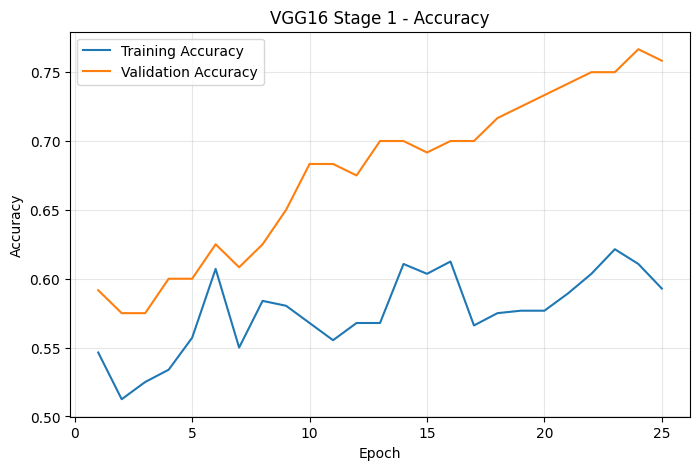

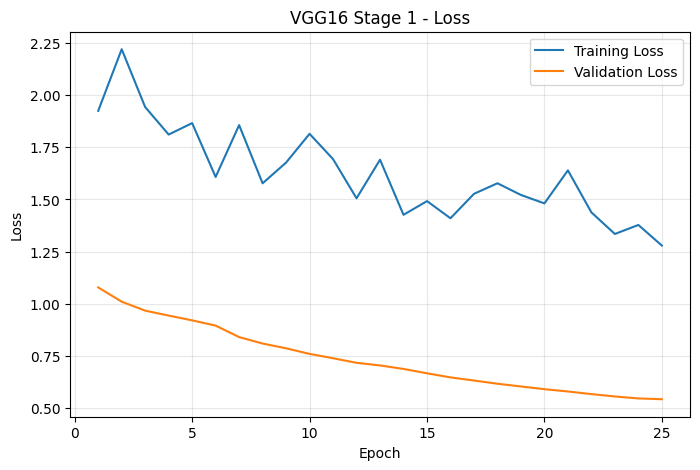

VGG16 - STAGE 1 ANALYSIS
Epochs completed:              25
Best epoch by val_loss:        25
Best validation loss:          0.5429
Validation accuracy at best:   0.7583

Highest validation accuracy:   0.7667
Highest val accuracy epoch:    24

Final training accuracy:       0.5929
Final validation accuracy:     0.7583
Final training loss:           1.2792
Final validation loss:         0.5429

Early stopping activated:      NO
Reason:                        25-epoch limit reached
Validation loss at epoch 25:   STILL IMPROVING
Test set used:                 NO
STAGE 1 ANALYSIS COMPLETE


In [ ]:
# VGG16 (Stage 1 training analysis)

# Extracting the stage 1 history
stage1_epochs = range(
    1,
    len(history_stage1.history["loss"]) + 1
)

train_accuracy = history_stage1.history["accuracy"]
val_accuracy = history_stage1.history["val_accuracy"]

train_loss = history_stage1.history["loss"]
val_loss = history_stage1.history["val_loss"]

# Best epoch

best_epoch = int(
    np.argmin(val_loss) + 1
)

best_val_loss = float(
    np.min(val_loss)
)

best_val_accuracy = float(
    val_accuracy[best_epoch - 1]
)

highest_val_accuracy = float(
    np.max(val_accuracy)
)

highest_val_accuracy_epoch = int(
    np.argmax(val_accuracy) + 1
)

# Accuracy curve

plt.figure(figsize=(8, 5))

plt.plot(
    stage1_epochs,
    train_accuracy,
    label="Training Accuracy"
)

plt.plot(
    stage1_epochs,
    val_accuracy,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("VGG16 Stage 1 - Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Loss curve

plt.figure(figsize=(8, 5))

plt.plot(
    stage1_epochs,
    train_loss,
    label="Training Loss"
)

plt.plot(
    stage1_epochs,
    val_loss,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VGG16 Stage 1 - Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Analysis summary

print("=" * 65)
print("VGG16 - STAGE 1 ANALYSIS")
print("=" * 65)

print(f"Epochs completed:              {len(train_loss)}")
print(f"Best epoch by val_loss:        {best_epoch}")
print(f"Best validation loss:          {best_val_loss:.4f}")
print(
    f"Validation accuracy at best:   "
    f"{best_val_accuracy:.4f}"
)

print()
print(
    f"Highest validation accuracy:   "
    f"{highest_val_accuracy:.4f}"
)
print(
    f"Highest val accuracy epoch:    "
    f"{highest_val_accuracy_epoch}"
)

print()
print(
    f"Final training accuracy:       "
    f"{train_accuracy[-1]:.4f}"
)
print(
    f"Final validation accuracy:     "
    f"{val_accuracy[-1]:.4f}"
)
print(
    f"Final training loss:           "
    f"{train_loss[-1]:.4f}"
)
print(
    f"Final validation loss:         "
    f"{val_loss[-1]:.4f}"
)

print()
print("Early stopping activated:      NO")
print("Reason:                        25-epoch limit reached")
print("Validation loss at epoch 25:   STILL IMPROVING")
print("Test set used:                 NO")

print("=" * 65)
print("STAGE 1 ANALYSIS COMPLETE")

In [ ]:

# VGG16 (Stage 2 fine-tuning configuration)



# Ensuring we start from the best Stage 1 model weights


model.load_weights(
    STAGE1_CHECKPOINT
)


# Enable backbone fine-tuning

vgg16_base.trainable = True

# Freezing Blocks 1-4.
# Unfreezing Block 5 only.
for layer in vgg16_base.layers:

    if layer.name.startswith("block5"):
        layer.trainable = True
    else:
        layer.trainable = False

# Counting the trainable parameters

trainable_backbone_layers = [
    layer.name
    for layer in vgg16_base.layers
    if layer.trainable
]

frozen_backbone_layers = [
    layer.name
    for layer in vgg16_base.layers
    if not layer.trainable
]

trainable_params = sum(
    np.prod(variable.shape)
    for variable in model.trainable_weights
)

non_trainable_params = sum(
    np.prod(variable.shape)
    for variable in model.non_trainable_weights
)

# Displaying the configuration

print("=" * 65)
print("VGG16 - STAGE 2 FINE-TUNING CONFIGURATION")
print("=" * 65)

print("Stage 1 checkpoint:       LOADED")
print("VGG16 backbone:           PARTIALLY UNFROZEN")

print()
print("Frozen sections:          Blocks 1-4")
print("Trainable section:        Block 5")

print()
print("Trainable Block 5 layers:")

for layer_name in trainable_backbone_layers:
    print(f"  ✓ {layer_name}")

print()
print(
    f"Trainable parameters:     "
    f"{trainable_params:,}"
)

print(
    f"Non-trainable parameters: "
    f"{non_trainable_params:,}"
)


# Safety checks

if not trainable_backbone_layers:
    raise RuntimeError(
        "No VGG16 backbone layers were unfrozen."
    )

if any(
    not name.startswith("block5")
    for name in trainable_backbone_layers
):
    raise RuntimeError(
        "Unexpected VGG16 layers were unfrozen."
    )

print()
print("Fine-tuning LR:           1e-5")
print("Maximum Stage 2 epochs:   15")
print("Test set:                 STILL LOCKED")

print("=" * 65)
print("VGG16 STAGE 2 CONFIGURATION VERIFIED")

VGG16 - STAGE 2 FINE-TUNING CONFIGURATION
Stage 1 checkpoint:       LOADED
VGG16 backbone:           PARTIALLY UNFROZEN

Frozen sections:          Blocks 1-4
Trainable section:        Block 5

Trainable Block 5 layers:
  ✓ block5_conv1
  ✓ block5_conv2
  ✓ block5_conv3
  ✓ block5_pool

Trainable parameters:     7,079,937
Non-trainable parameters: 7,635,264

Fine-tuning LR:           1e-5
Maximum Stage 2 epochs:   15
Test set:                 STILL LOCKED
VGG16 STAGE 2 CONFIGURATION VERIFIED


In [ ]:
# VGG16 (Stage 2 compilation and callbacks)

FINE_TUNE_LEARNING_RATE = 1e-5
MAX_FINE_TUNE_EPOCHS = 15

# Recompiling for fine-tuning

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LEARNING_RATE
    ),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[
        keras.metrics.BinaryAccuracy(
            name="accuracy"
        )
    ]
)

# Stage 2 checkpoint

STAGE2_CHECKPOINT = (
    VGG16_CHECKPOINT_DIR /
    "VGG16_stage2_best.keras"
)

# Stage 2 callbacks

stage2_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=str(STAGE2_CHECKPOINT),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

# Verification

current_lr = float(
    tf.keras.backend.get_value(
        model.optimizer.learning_rate
    )
)

print("=" * 65)
print("VGG16 - STAGE 2 PRE-TRAINING CHECK")
print("=" * 65)

print("Starting point:            Best Stage 1 checkpoint")
print("Trainable VGG16 section:  Block 5")
print("Frozen VGG16 sections:    Blocks 1-4")

print()
print("Optimizer:                 Adam")
print(f"Learning rate:             {current_lr:.7f}")
print("Loss:                      Binary Cross-Entropy")
print("Metric:                    Binary Accuracy")

print()
print("Maximum epochs:            15")
print("Early stopping patience:   5")
print("LR reduction patience:     2")
print("Checkpoint monitor:        val_loss")

print()
print("Stage 2 checkpoint:")
print(STAGE2_CHECKPOINT)

print()
print("Test set:                  LOCKED / NOT LOADED")

print("=" * 65)
print("VGG16 READY FOR STAGE 2 FINE-TUNING")

VGG16 - STAGE 2 PRE-TRAINING CHECK
Starting point:            Best Stage 1 checkpoint
Trainable VGG16 section:  Block 5
Frozen VGG16 sections:    Blocks 1-4

Optimizer:                 Adam
Learning rate:             0.0000100
Loss:                      Binary Cross-Entropy
Metric:                    Binary Accuracy

Maximum epochs:            15
Early stopping patience:   5
LR reduction patience:     2
Checkpoint monitor:        val_loss

Stage 2 checkpoint:
/content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/VGG16/VGG16_stage2_best.keras

Test set:                  LOCKED / NOT LOADED
VGG16 READY FOR STAGE 2 FINE-TUNING


In [ ]:

# VGG16 (Stage 2 fine-tuning)

print("=" * 65)
print("VGG16 - STARTING STAGE 2 FINE-TUNING")
print("=" * 65)

print("Starting point:   Best Stage 1 checkpoint")
print("Trainable block:  Block 5")
print("Learning rate:    1e-5")
print("Maximum epochs:   15")
print("Test set:         NOT USED")

print("=" * 65)

# Recording the start time

stage2_start_time = time.time()

# Fine-tune model

history_stage2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_FINE_TUNE_EPOCHS,
    callbacks=stage2_callbacks,
    verbose=1
)


# Recording the duration

stage2_end_time = time.time()

stage2_duration_seconds = (
    stage2_end_time - stage2_start_time
)

stage2_duration_minutes = (
    stage2_duration_seconds / 60
)

# Extracting the results

stage2_epochs_completed = len(
    history_stage2.history["loss"]
)

stage2_best_epoch = int(
    np.argmin(
        history_stage2.history["val_loss"]
    ) + 1
)

stage2_best_val_loss = float(
    np.min(
        history_stage2.history["val_loss"]
    )
)

stage2_val_accuracy_at_best = float(
    history_stage2.history["val_accuracy"][
        stage2_best_epoch - 1
    ]
)

stage2_highest_val_accuracy = float(
    np.max(
        history_stage2.history["val_accuracy"]
    )
)

stage2_highest_accuracy_epoch = int(
    np.argmax(
        history_stage2.history["val_accuracy"]
    ) + 1
)

# Summary

print("\n" + "=" * 65)
print("VGG16 - STAGE 2 FINE-TUNING COMPLETE")
print("=" * 65)

print(
    f"Epochs completed:             "
    f"{stage2_epochs_completed}"
)

print(
    f"Best epoch by val_loss:       "
    f"{stage2_best_epoch}"
)

print(
    f"Best validation loss:         "
    f"{stage2_best_val_loss:.4f}"
)

print(
    f"Validation accuracy at best:  "
    f"{stage2_val_accuracy_at_best:.4f}"
)

print(
    f"Highest validation accuracy:  "
    f"{stage2_highest_val_accuracy:.4f}"
)

print(
    f"Highest accuracy epoch:       "
    f"{stage2_highest_accuracy_epoch}"
)

print(
    f"Training duration:            "
    f"{stage2_duration_minutes:.2f} minutes"
)

print()
print("Best Stage 2 checkpoint:")
print(STAGE2_CHECKPOINT)

print()
print("Test set used:                NO")

print("=" * 65)

VGG16 - STARTING STAGE 2 FINE-TUNING
Starting point:   Best Stage 1 checkpoint
Trainable block:  Block 5
Learning rate:    1e-5
Maximum epochs:   15
Test set:         NOT USED
Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6452 - loss: 1.1682
Epoch 1: val_loss improved from None to 0.43322, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/VGG16/VGG16_stage2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/VGG16/VGG16_stage2_best.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 79s 4s/step - accuracy: 0.6500 - loss: 1.0813 - val_accuracy: 0.8417 - val_loss: 0.4332 - learning_rate: 1.0000e-05
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6927 - loss: 0.7289
Epoch 2: val_loss improved from 0.43322 to 0.37475, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/VGG16/VGG16_stage2_best.keras

Epoch 2: finished saving model to /content/drive/MyD

In [ ]:
# VGG16 (Saving standerdised development outputs)

# Output directories

FIGURE_DIR = RESULTS_ROOT / "Figures" / "VGG16"
HISTORY_DIR = RESULTS_ROOT / "Training_History"
METRICS_DIR = RESULTS_ROOT / "Metrics"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
HISTORY_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# Combining the Stage 1 and Stage 2 histories


stage1_df = pd.DataFrame(
    history_stage1.history
)

stage1_df.insert(
    0,
    "epoch",
    range(1, len(stage1_df) + 1)
)

stage1_df.insert(
    0,
    "stage",
    "stage1"
)

stage2_df = pd.DataFrame(
    history_stage2.history
)

stage2_df.insert(
    0,
    "epoch",
    range(1, len(stage2_df) + 1)
)

stage2_df.insert(
    0,
    "stage",
    "stage2"
)

combined_history = pd.concat(
    [stage1_df, stage2_df],
    ignore_index=True
)

history_path = (
    HISTORY_DIR /
    "VGG16_training_history.csv"
)

combined_history.to_csv(
    history_path,
    index=False
)

# Saving the development metrics

development_metrics = pd.DataFrame([
    {
        "model": "VGG16",
        "selected_stage": "stage2",
        "selection_criterion": "val_loss",
        "stage1_best_val_loss": best_val_loss,
        "stage1_val_accuracy_at_best": best_val_accuracy,
        "stage2_best_epoch": stage2_best_epoch,
        "stage2_best_val_loss": stage2_best_val_loss,
        "stage2_val_accuracy_at_best":
            stage2_val_accuracy_at_best,
        "stage1_training_minutes":
            stage1_duration_minutes,
        "stage2_training_minutes":
            stage2_duration_minutes,
        "total_training_minutes":
            stage1_duration_minutes +
            stage2_duration_minutes
    }
])

metrics_path = (
    METRICS_DIR /
    "VGG16_development_metrics.csv"
)

development_metrics.to_csv(
    metrics_path,
    index=False
)

# Saving the configuration

vgg16_configuration = {
    "model": "VGG16",
    "pretrained_weights": "ImageNet",
    "input_shape": [224, 224, 3],
    "batch_size": 32,
    "random_seed": 42,

    "classes": {
        "0": "tb_negative",
        "1": "tb_positive"
    },

    "training_images": 560,
    "validation_images": 120,

    "stage1": {
        "backbone": "frozen",
        "learning_rate": 1e-4,
        "maximum_epochs": 25
    },

    "stage2": {
        "trainable_section": "block5",
        "frozen_sections": "blocks1-4",
        "learning_rate": 1e-5,
        "maximum_epochs": 15,
        "best_epoch": stage2_best_epoch
    },

    "augmentation": {
        "rotation_degrees": 5,
        "translation": 0.05,
        "zoom": 0.10,
        "contrast": 0.10,
        "horizontal_flip": False,
        "vertical_flip": False
    },

    "optimizer": "Adam",
    "loss": "BinaryCrossentropy",
    "checkpoint_monitor": "val_loss",

    "selected_checkpoint":
        str(STAGE2_CHECKPOINT),

    "test_set_used_during_development":
        False
}

config_path = (
    METRICS_DIR /
    "VGG16_configuration.json"
)

with open(config_path, "w") as file:
    json.dump(
        vgg16_configuration,
        file,
        indent=4
    )

# Verification

print("=" * 65)
print("VGG16 - DEVELOPMENT OUTPUTS SAVED")
print("=" * 65)

print("Training history:")
print(history_path)

print("\nDevelopment metrics:")
print(metrics_path)

print("\nConfiguration:")
print(config_path)

print("\nSelected checkpoint:")
print(STAGE2_CHECKPOINT)

print()
print("Selected configuration:   STAGE 2")
print("Selection criterion:      Lowest validation loss")
print("Best validation loss:     0.3106")
print("Validation accuracy:      90.83%")
print("Test set used:            NO")

print("=" * 65)
print("VGG16 DEVELOPMENT RESULTS SAVED SUCCESSFULLY")

VGG16 - DEVELOPMENT OUTPUTS SAVED
Training history:
/content/drive/MyDrive/Insight_Hunters_Project/04_Results/Training_History/VGG16_training_history.csv

Development metrics:
/content/drive/MyDrive/Insight_Hunters_Project/04_Results/Metrics/VGG16_development_metrics.csv

Configuration:
/content/drive/MyDrive/Insight_Hunters_Project/04_Results/Metrics/VGG16_configuration.json

Selected checkpoint:
/content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/VGG16/VGG16_stage2_best.keras

Selected configuration:   STAGE 2
Selection criterion:      Lowest validation loss
Best validation loss:     0.3106
Validation accuracy:      90.83%
Test set used:            NO
VGG16 DEVELOPMENT RESULTS SAVED SUCCESSFULLY


In [ ]:
# VGG16 (Final development verification)

# The required VGG16 development files

required_outputs = {
    "Stage 1 checkpoint":
        STAGE1_CHECKPOINT,

    "Stage 2 checkpoint":
        STAGE2_CHECKPOINT,

    "Training history":
        history_path,

    "Development metrics":
        metrics_path,

    "Model configuration":
        config_path
}

# Verifying the files

print("=" * 65)
print("VGG16 - FINAL DEVELOPMENT VERIFICATION")
print("=" * 65)

all_outputs_present = True

for output_name, output_path in required_outputs.items():

    exists = Path(output_path).exists()

    status = "✓" if exists else "✗"

    print(
        f"{status} {output_name}"
    )

    if not exists:
        all_outputs_present = False

# Final candidate information

print()
print("Selected architecture:       VGG16")
print("Selected development stage:  Stage 2 - Fine-Tuned")
print("Fine-tuned section:          Block 5")
print("Selection criterion:         Lowest validation loss")

print()
print("Best validation loss:        0.3106")
print("Validation accuracy:         90.83%")

print()
print("Selected checkpoint:")
print(STAGE2_CHECKPOINT)

print()
print("Test set used during")
print("model development:           NO")

print("-" * 65)

if not all_outputs_present:
    raise FileNotFoundError(
        "One or more required VGG16 outputs are missing."
    )

print("ALL REQUIRED VGG16 DEVELOPMENT OUTPUTS VERIFIED")
print("VGG16 CANDIDATE CONFIGURATION LOCKED")
print("=" * 65)

VGG16 - FINAL DEVELOPMENT VERIFICATION
✓ Stage 1 checkpoint
✓ Stage 2 checkpoint
✓ Training history
✓ Development metrics
✓ Model configuration

Selected architecture:       VGG16
Selected development stage:  Stage 2 - Fine-Tuned
Fine-tuned section:          Block 5
Selection criterion:         Lowest validation loss

Best validation loss:        0.3106
Validation accuracy:         90.83%

Selected checkpoint:
/content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/VGG16/VGG16_stage2_best.keras

Test set used during
model development:           NO
-----------------------------------------------------------------
ALL REQUIRED VGG16 DEVELOPMENT OUTPUTS VERIFIED
VGG16 CANDIDATE CONFIGURATION LOCKED
